# Football transfer valuation: walkthrough

Predicting a player's Transfermarkt market value at the time of a transfer from the previous season's FBref stats and the clubs involved. This notebook reads the outputs of `python -m src.train` and shows the data, the two silent bugs, the fixes and the results.

In [1]:
import json, sys
from pathlib import Path
import numpy as np, pandas as pd
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.config import DATASET, BUILD_STATS, TM_VALUATIONS, FBREF_STATS, RAW_FBREF_DIR
pd.set_option('display.width', 120)

## 1. The dataset

One row per transfer, joined to the player's FBref season before the move. Training seasons end 2019 to 2024; 2025 is held out.

In [2]:
df = pd.read_parquet(DATASET)
print(df.shape)
df.groupby('season_end_year').size().rename('transfers').to_frame().T

(6706, 81)


season_end_year,2019,2020,2021,2022,2023,2024,2025
transfers,600,657,663,847,1202,1324,1413


In [3]:
stats = json.loads(BUILD_STATS.read_text())
n = stats['transfers_in_window']
pd.DataFrame({'transfers': stats, 'share of window': {k: f'{v / n:.2%}' for k, v in stats.items()}})

,transfers,share of window
transfers_in_window,54698,100.00%
name_season_matches,8039,14.70%
birth_year_matches,7749,14.17%
verified_matches,7741,14.15%
model_rows,6706,12.26%


## 2. Why the name join needed a birth year

The FBref source keeps one row per name per season across all ten leagues, so namesakes are summed. 'Fernando' at Almeria in 2022-23 played 89 league matches, which is impossible.

In [4]:
raw = pd.read_csv(RAW_FBREF_DIR / 'fifa_fbref_merged.csv', low_memory=False,
                  usecols=['player', 'team', 'league', 'season', 'Playing Time_MP', 'Playing Time_Min', 'born_fbref', 'long_name'])
raw[(raw.player == 'Fernando') & (raw.season == 2223)]

,long_name,season,player,Playing Time_MP,Playing Time_Min,league,team,born_fbref
4461,Fernando Francisco Reges,2223,Fernando,89,7444.0,ESP-La Liga,Almería,1990.0
5576,Fernando Martinez Rubio,2223,Fernando,89,7444.0,ESP-La Liga,Almería,1990.0
6941,Fernando Andrade dos Santos,2223,Fernando,89,7444.0,ESP-La Liga,Almería,1990.0


In [5]:
raw.groupby(['player', 'season'])['team'].nunique().max()  # never more than one row per name and season

np.int64(1)

## 3. Silent bug 1: position flags were always zero

The flags compared Transfermarkt's `position` with FBref codes (GK, DF, MF, FW). The column actually holds the labels below, so the original check matched nothing.

In [6]:
print(df['position'].value_counts())
print('old check matches:', df['position'].str.upper().isin(['GK', 'DF', 'MF', 'FW']).sum())
df[['is_goalkeeper', 'is_defender', 'is_midfielder', 'is_forward']].sum()

position
Defender      2219
Attack        2162
Midfield      1878
Goalkeeper     447
Name: count, dtype: int64
old check matches: 0


is_goalkeeper     447
is_defender      2219
is_midfielder    1878
is_forward       2162
dtype: int64

## 4. Silent bug 2: the contract feature, and a third in the club features

The contract feature first used a 2025 contract snapshot for transfers back to 2018; its replacement used the date of the player's *next* transfer (future information). It is removed. The club-level features had the same kind of problem: `current_club_id` in the valuations is the scrape-time club, identical across a player's whole history.

In [7]:
vals = pd.read_parquet(TM_VALUATIONS)
per_player = vals.groupby('player_id')['current_club_id'].nunique()
print('players with more than one club across all their valuations:', int((per_player > 1).sum()))

players with more than one club across all their valuations: 0


## 5. Results

In [8]:
from IPython.display import Markdown
text = (ROOT / 'results' / 'metrics.md').read_text(encoding='utf-8')
Markdown(text.split('## Test R squared by position')[0])

# Results

Test set: 1,413 transfers in the 2025 season. Training set: 5,293 transfers in earlier seasons. Target: log(1 + Transfermarkt market value at transfer). R squared, MAE and RMSE are on that log scale; the median absolute error is in euros.

Regenerate with `python -m src.train` (full pipeline) or `python -m src.evaluate` (report only).

## 3 x 2 factorial, test set

| Model | Features | Test R squared | MAE | RMSE | Median abs. error |
|---|---|---|---|---|---|
| Ridge | Traditional | 0.799 | 0.471 | 0.604 | EUR 1.14m |
| Ridge | With modern | 0.804 | 0.466 | 0.597 | EUR 1.19m |
| Random Forest | Traditional | 0.787 | 0.481 | 0.623 | EUR 1.13m |
| Random Forest | With modern | 0.786 | 0.483 | 0.625 | EUR 1.16m |
| XGBoost | Traditional | 0.808 | 0.460 | 0.592 | EUR 1.05m |
| XGBoost | With modern | 0.816 | 0.452 | 0.579 | EUR 1.09m |

## Trivial baselines (fit on training seasons)

| Baseline | Test R squared | MAE | RMSE |
|---|---|---|---|
| Global mean | -0.004 | 1.093 | 1.352 |
| Per-position mean | 0.005 | 1.091 | 1.346 |
| Per-league mean | 0.290 | 0.906 | 1.138 |



In [9]:
Markdown((ROOT / 'results' / 'fix_log.md').read_text(encoding='utf-8').split('## Match rate')[0])

# What each fix did

Test set: 2025 transfers. Train: all earlier seasons. Target: log1p(market value).
Every row is a full rerun of the pipeline from raw data after that fix.
Values are rounded to 3 decimals; where a run log printed 4 decimals ending in 5,
the exact value from the saved model was used when available.

## Test R squared

| Step | Rows (train / test) | Ridge trad | Ridge modern | RF trad | RF modern | XGB trad | XGB modern | Global mean | Position mean | League mean |
|---|---|---|---|---|---|---|---|---|---|---|
| Paper (submitted) | 5,575 / 1,462 | 0.581 | 0.601 | 0.651 | 0.659 | 0.688 | 0.719 | -0.002 | 0.003 | 0.285 |
| 0. Original code, rebuilt from raw | 5,575 / 1,462 | 0.573 | 0.587 | 0.651 | 0.660 | 0.687 | 0.718 | | | |
| 1. Add trivial baselines | 5,575 / 1,462 | 0.573 | 0.587 | 0.651 | 0.660 | 0.687 | 0.718 | -0.002 | 0.003 | 0.285 |
| 2. Name + birth year join, drop impossible rows | 5,293 / 1,413 | 0.641 | 0.671 | 0.665 | 0.672 | 0.712 | 0.737 | -0.004 | 0.005 | 0.290 |
| 3. Position flags mapped to Transfermarkt labels | 5,293 / 1,413 | 0.646 | 0.678 | 0.663 | 0.672 | 0.710 | 0.736 | -0.004 | 0.005 | 0.290 |
| 4. Contract feature removed | 5,293 / 1,413 | 0.650 | 0.681 | 0.662 | 0.674 | 0.715 | 0.742 | -0.004 | 0.005 | 0.290 |
| 5. Point-in-time club levels | 5,293 / 1,413 | 0.799 | 0.804 | 0.787 | 0.786 | 0.808 | 0.816 | -0.004 | 0.005 | 0.290 |
| 6. Early stopping: untuned path fixed, tested | 5,293 / 1,413 | 0.799 | 0.804 | 0.787 | 0.786 | 0.808 | 0.816 | -0.004 | 0.005 | 0.290 |
| 7. Ridge scaling verified by test (no code change) | 5,293 / 1,413 | 0.799 | 0.804 | 0.787 | 0.786 | 0.808 | 0.816 | -0.004 | 0.005 | 0.290 |

## Early stopping before / after (brief issue 1)

The tuned pipeline already early-stopped on 2024, inside the training
seasons, and refit on all training seasons; a test now checks that every
eval_set XGBoost sees holds only 2024 rows. The untuned path set
early_stopping_rounds with no eval_set, which XGBoost 3.1.3 rejects
("Must have at least 1 validation dataset for early stopping"); it now uses
the same 2024 holdout. Deliberate comparison, same tuned hyperparameters
(src/early_stopping_check.py):

| XGBoost | Early stop on 2025 test (leaky) | Early stop on 2024 (correct) |
|---|---|---|
| Traditional: rounds / test R squared | 932 / 0.810 | 572 / 0.808 |
| With modern: rounds / test R squared | 966 / 0.816 | 833 / 0.816 |

Early stopping on the test set would have flattered R squared by at most
0.003 here.

Contract ablation: step 3 is the run with the leaky contract feature
(years until the next transfer, snapshot fallback for 2023+ transfers);
step 4 is the same pipeline without it. Removing it did not lower test
R squared (XGBoost modern 0.736 to 0.742). The leak did not inflate the
2025 score because most 2025 transfers have no later transfer yet, so their
values came from the snapshot fallback while training rows used the future
transfer date: the feature meant different things in train and test.
Checked on the model rows: 80.7% of training rows took the value from the
next transfer, against 27.3% of 2025 test rows (72.7% snapshot or missing).

Club levels (step 5): the old feature grouped valuations by
`current_club_id`, which is each player's club at scrape time (one value per
player across all 496,606 valuations), so a club's "level" in 2019 was built
from its 2025 squad, with an all-time fallback. The new feature dates each
valuation's club from the transfer history and takes the median over the
12 months strictly before the transfer, excluding the transferring player.
Coverage on model rows rose from 92.6% / 88.0% (from / to) to 99.0% / 97.8%.

The large R squared gain was checked for leakage with Ridge (traditional):

| Club level window | Ridge test R squared |
|---|---|
| 12 months ending the day before the transfer (as built) | 0.798 |
| 12 months ending 90 days before the transfer | 0.800 |
| 12 months ending 365 days before the transfer | 0.796 |
| No club features | 0.639 |

The score does not depend on valuations close to the transfer, so the gain
comes from measuring club strength correctly, not from leaked information.
Caveat: only valuations of players with at least one recorded transfer can be
dated (160,636 of 496,606, 32.3%).



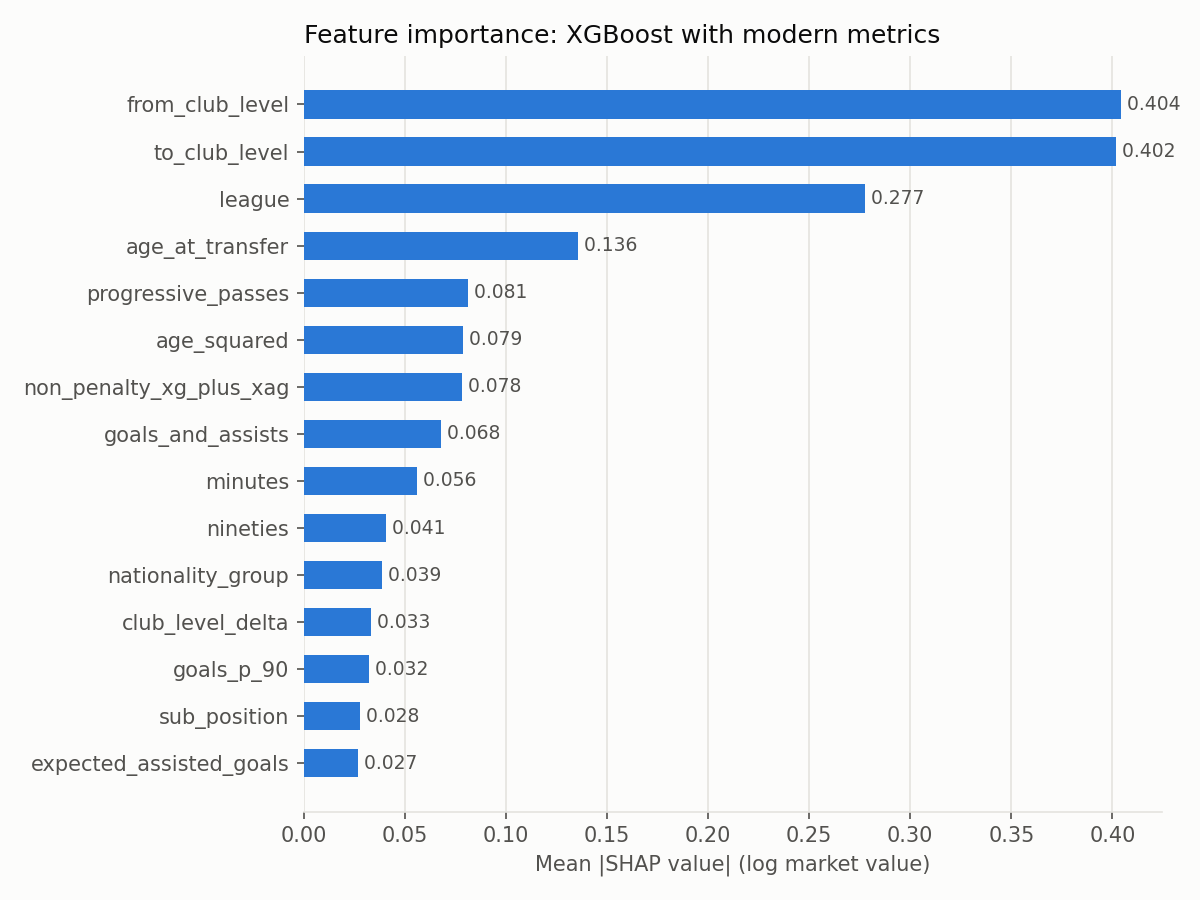

In [10]:
from IPython.display import Image
Image(str(ROOT / 'results' / 'feature_importance.png'), width=640)

## 6. Where the model is wrong

Largest 2025 errors for XGBoost with modern metrics, in euros.

In [11]:
import joblib
from src.config import MODEL_DIR
b = joblib.load(MODEL_DIR / 'xgboost_with_modern.joblib')
test = df[df.season_end_year == 2025].copy()
test['predicted_eur'] = np.expm1(b['model'].predict(b['preprocessor'].transform(test[b['num_cols'] + b['cat_cols']])))
test['ratio'] = test['predicted_eur'] / test['market_value_eur_at_transfer']
cols = ['player', 'transfer_date', 'league', 'age_at_transfer', 'market_value_eur_at_transfer', 'predicted_eur', 'ratio']
test.loc[test['ratio'].sub(1).abs().sort_values(ascending=False).index[:8], cols].round(2)

,player,transfer_date,league,age_at_transfer,market_value_eur_at_transfer,predicted_eur,ratio
6666,Diego López,2024-07-04,La Liga,22.70,100000.0,2.045792e+06,20.46
5230,Ramon Hendriks,2024-07-01,Eredivisie,22.95,800000.0,6.498489e+06,8.12
84,José Fonte,2024-07-10,Primeira Liga,40.55,100000.0,6.261121e+05,6.26
6607,Gavin Beavers,2025-01-22,MLS,19.73,350000.0,1.647341e+06,4.71
6438,Enzo Barrenechea,2024-07-01,Serie A,23.11,7500000.0,3.345648e+07,4.46
2322,Ben Osborn,2024-07-01,Premier League,29.91,1000000.0,4.316510e+06,4.32
3405,Lazaros Lamprou,2025-06-30,Eredivisie,27.53,450000.0,1.905864e+06,4.24
3404,Lazaros Lamprou,2025-01-01,Eredivisie,27.04,450000.0,1.843601e+06,4.10


In [12]:
print('share of 2025 predictions within a factor of 2 of the real value:',
      f"{((test.ratio > 0.5) & (test.ratio < 2)).mean():.1%}")

share of 2025 predictions within a factor of 2 of the real value: 77.7%
